# How a spike pattern acquires a movement
Hold the sensory input fixed. The policy (the **actor**) scores the three movements using the nine filtered rates and a constant bias, $p(a\mid f)=\operatorname{softmax}(Wf)_a$. The **critic** uses its own weights to estimate future reward, $V(f)=w_c^\mathsf{T}f$. At initialization the three moves have equal probability.

This worked example isolates one update. We supply “down” as the example action and a terminal reward of $+1$. In the game, the policy samples its own action, and the simulator computes the reward.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from model import AssemblyConfig, PopulationActorCritic, SpikingAssemblies

network = SpikingAssemblies(AssemblyConfig(), seed=101)
for _ in range(120):
    network.step(0.2)
f = network.features()
actor = PopulationActorCritic(n_features=len(f))
before = actor.probabilities(f)
circuit_before = network.weights.copy()
delta = actor.learn(f, action=2, reward=1.0, next_features=f, terminal=True)
after = actor.probabilities(f)
assert after[2] > before[2]
np.testing.assert_array_equal(network.weights, circuit_before)
print(f'Prediction error {delta:+.2f}; down probability {before[2]:.3f} → {after[2]:.3f}')

Prediction error +1.00; down probability 0.333 → 0.351


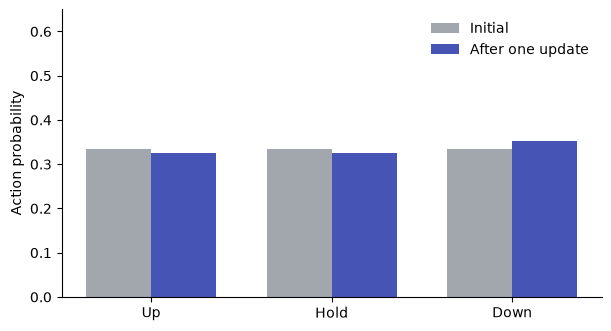

In [2]:
x = np.arange(3)
fig, ax = plt.subplots(figsize=(6, 3.2), layout='constrained')
ax.bar(x - 0.18, before, 0.36, color='#a2a7ae', label='Initial')
ax.bar(x + 0.18, after, 0.36, color='#4655b5', label='After one update')
ax.set(xticks=x, xticklabels=['Up', 'Hold', 'Down'], ylabel='Action probability', ylim=(0, 0.65))
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.show()

Across a full serve the learning rule uses the prediction error $\delta=r+\gamma V(f')-V(f)$ and a decaying record of recent spike features and actions, called an *eligibility trace*. A positive error strengthens the association between the recent pattern and the chosen action. The implementation clips the error to $[-2,2]$ and includes a small entropy term to encourage exploration.

**Try it.** Change the reward to $-1$, reverse the direction of the assertion, and watch what happens to “down.”